In [1]:
import sys
from pathlib import Path
raiz_projeto = Path().resolve().parent
if str(raiz_projeto) not in sys.path:
    sys.path.append(str(raiz_projeto))

import pandas as pd
from sqlalchemy import create_engine
import matplotlib.pyplot as plt
import seaborn as sns
from src import config
sns.set_theme(style="whitegrid")


engine = create_engine(config.DATABASE_URL)

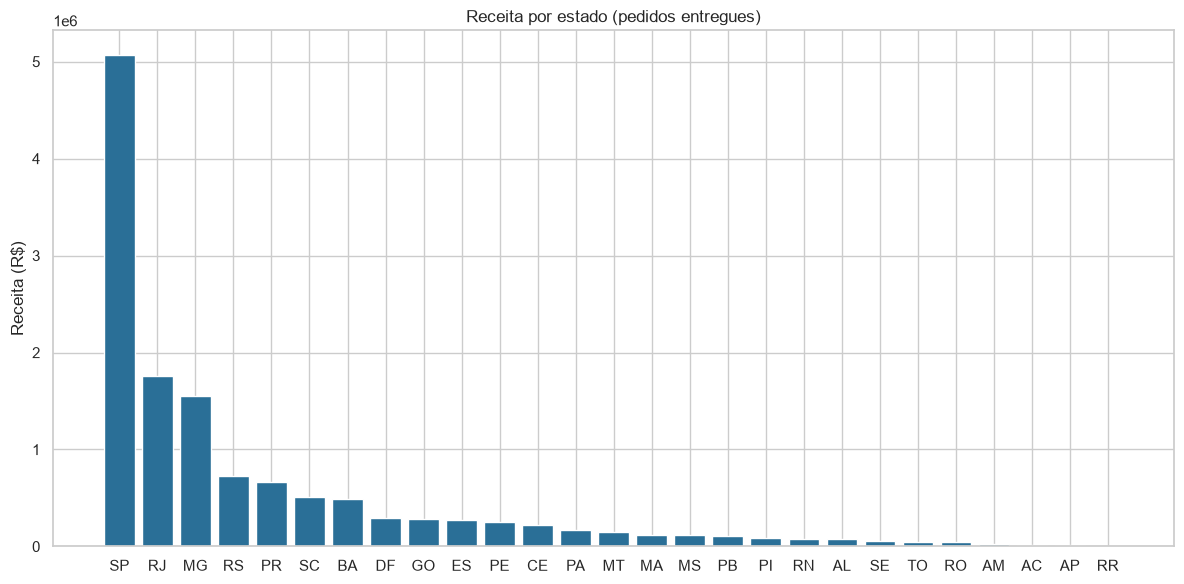

In [2]:
query_estado = """
SELECT
    c.customer_state,
    ROUND(SUM(oi.price)::numeric, 2) AS receita,
    COUNT(DISTINCT o.order_id) AS pedidos,
    ROUND((SUM(oi.price) / COUNT(DISTINCT o.order_id))::numeric, 2) AS ticket_medio
FROM orders o
JOIN order_items oi ON o.order_id = oi.order_id
JOIN customers c ON o.customer_id = c.customer_id
WHERE o.order_status = 'delivered'
GROUP BY c.customer_state
ORDER BY receita DESC;
"""
df_estado = pd.read_sql(query_estado, engine)

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(df_estado["customer_state"], df_estado["receita"], color="#2a6f97")
ax.set_title("Receita por estado (pedidos entregues)")
ax.set_ylabel("Receita (R$)")
plt.tight_layout()
plt.show()